# Series de tiempo y forecasting

Fases 1 y 2: preparación, auditoría, exploración y ventanas temporales. Los gráficos describen el panel; no se usan para ajustar modelos con datos de prueba. Los datos se descargan y procesan por bloques.

## Preparar el panel

La descarga ocupa cerca de 250 MB y el archivo original cerca de 680 MiB. El lector Parquet usa grupos de filas para evitar cargar el panel largo completo.

In [1]:
from pathlib import Path
import sys
import pandas as pd

ROOT = Path.cwd()
while not (ROOT / "src").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

RAW_PATH = ROOT / "data" / "raw" / "LD2011_2014.txt"
PANEL_PATH = ROOT / "data" / "processed" / "hourly.parquet"
CLIENT_IDS_PATH = ROOT / "data" / "processed" / "client_ids.csv"

from src.data.download import download_dataset
from src.data.preprocess import preprocess_dataset
from src.data.panel import load_panel_matrix

if not RAW_PATH.exists():
    download_dataset(RAW_PATH.parent)
if not PANEL_PATH.exists() or not CLIENT_IDS_PATH.exists():
    preprocess_dataset(RAW_PATH, PANEL_PATH, PANEL_PATH.parent, seed=42)

panel = load_panel_matrix(PANEL_PATH, CLIENT_IDS_PATH)
print({
    "clientes": len(panel.client_ids),
    "horas_por_cliente": len(panel.timestamps),
    "desde": panel.timestamps[0],
    "hasta": panel.timestamps[-1],
    "forma_y": panel.values.shape,
})

{'clientes': 370, 'horas_por_cliente': 35063, 'desde': Timestamp('2011-01-01 01:00:00'), 'hasta': Timestamp('2014-12-31 23:00:00'), 'forma_y': (370, 35063)}


## Exploración

Se comparan perfiles horarios y semanales, feriados nacionales portugueses, escalas por cliente y el período de Navidad y Año Nuevo. Los promedios por cliente para normalización se calculan solo con entrenamiento.

In [2]:
from src.data.eda import run_eda

eda_summary = run_eda(PANEL_PATH, CLIENT_IDS_PATH, ROOT / "outputs")
display(eda_summary)
display(pd.DataFrame(eda_summary["window_counts"]))
display(pd.read_csv(ROOT / "outputs" / "metrics" / "portugal_holidays.csv"))

{'client_count': 370,
 'hourly_rows_per_client': 35063,
 'first_timestamp': '2011-01-01 01:00:00',
 'last_timestamp': '2014-12-31 23:00:00',
 'train_mean_hourly_kwh_min': 0.0,
 'train_mean_hourly_kwh_median': 120.68912219751235,
 'train_mean_hourly_kwh_max': 48816.55244883041,
 'portugal_public_holiday_dates': 44,
 'calendar_features_cyclic': 7,
 'calendar_features_onehot': 44,
 'window_counts': [{'split': 'train',
   'origins_per_client': 21865,
   'windows_all_clients': 8090050,
   'daily_backtest_origins': 0},
  {'split': 'validation',
   'origins_per_client': 2185,
   'windows_all_clients': 808450,
   'daily_backtest_origins': 0},
  {'split': 'test',
   'origins_per_client': 2185,
   'windows_all_clients': 808450,
   'daily_backtest_origins': 92}],
 'normalization_note': 'Compare global and per-series scaling; fit statistics only on the training interval. Window scaling uses its history only.',
 'eda_scope': 'Descriptive plots use the available panel and are not used to tune models

,split,origins_per_client,windows_all_clients,daily_backtest_origins
0,train,21865,8090050,0
1,validation,2185,808450,0
2,test,2185,808450,92


,date,holiday
0,2011-01-01,Ano Novo
1,2011-04-22,Sexta-feira Santa
2,2011-04-24,Páscoa
3,2011-04-25,Dia da Liberdade
4,2011-05-01,Dia do Trabalhador
5,2011-06-10,"Dia de Portugal, de Camões e das Comunidades P..."
6,2011-06-23,Corpo de Deus
7,2011-08-15,Assunção de Nossa Senhora
8,2011-10-05,Implantação da República
9,2011-11-01,Dia de Todos os Santos


hourly_weekly_profiles.png


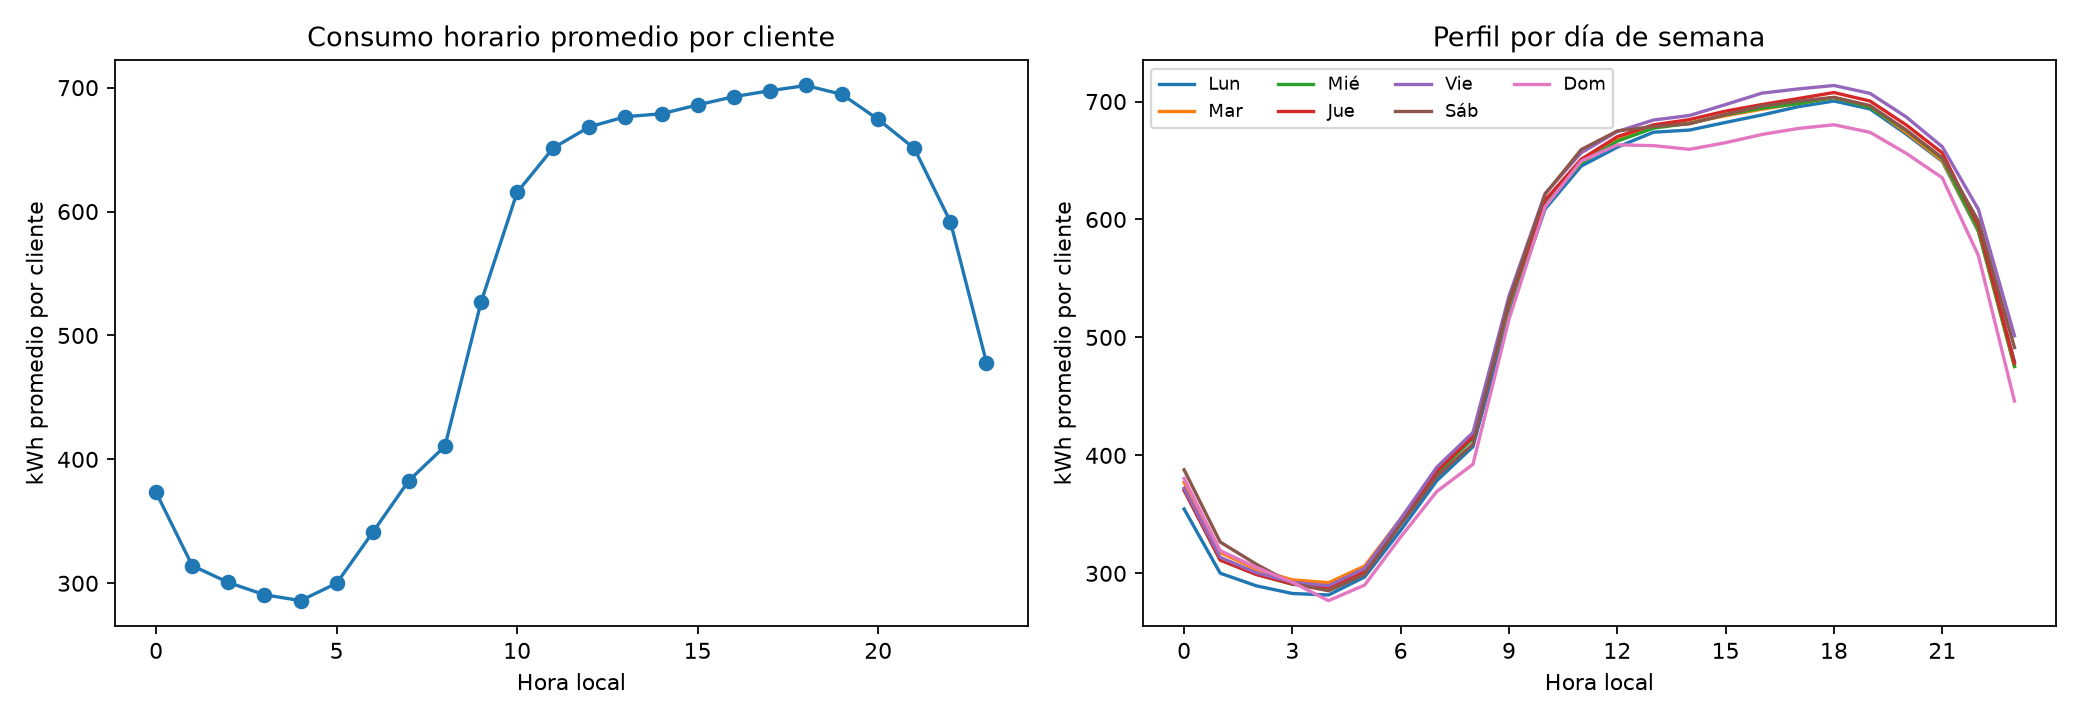

portugal_holidays.png


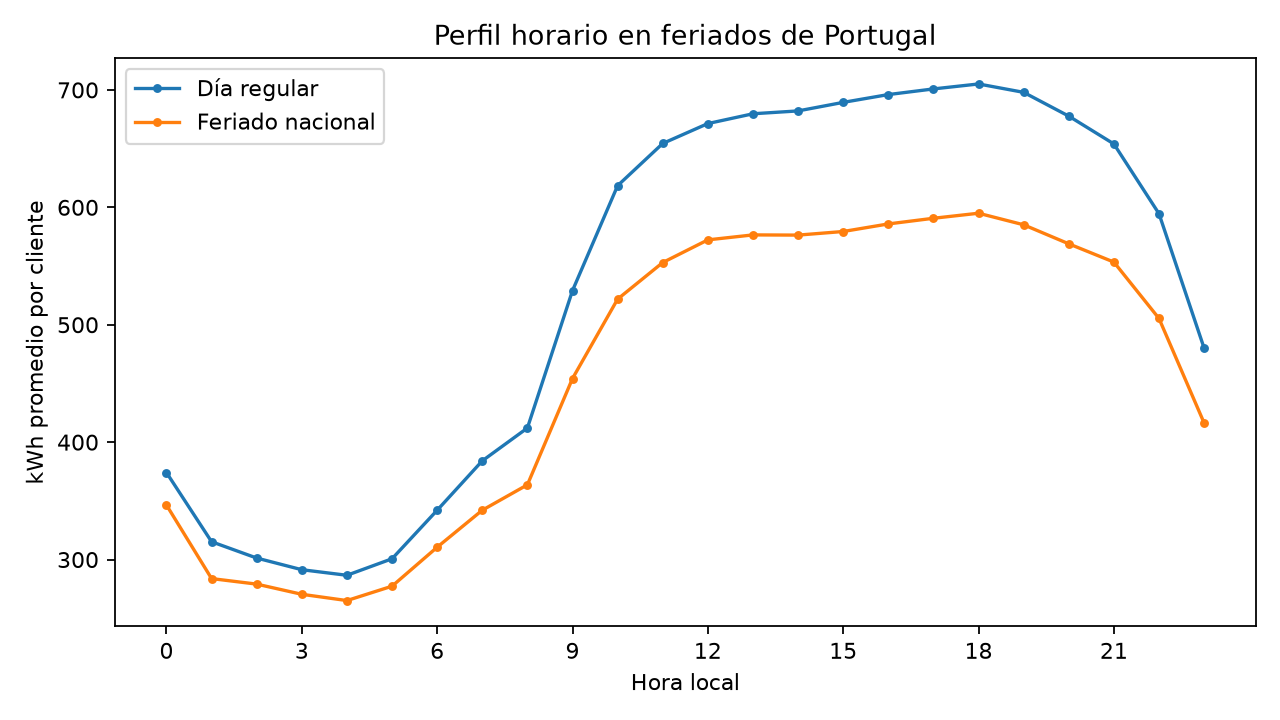

client_scales.png


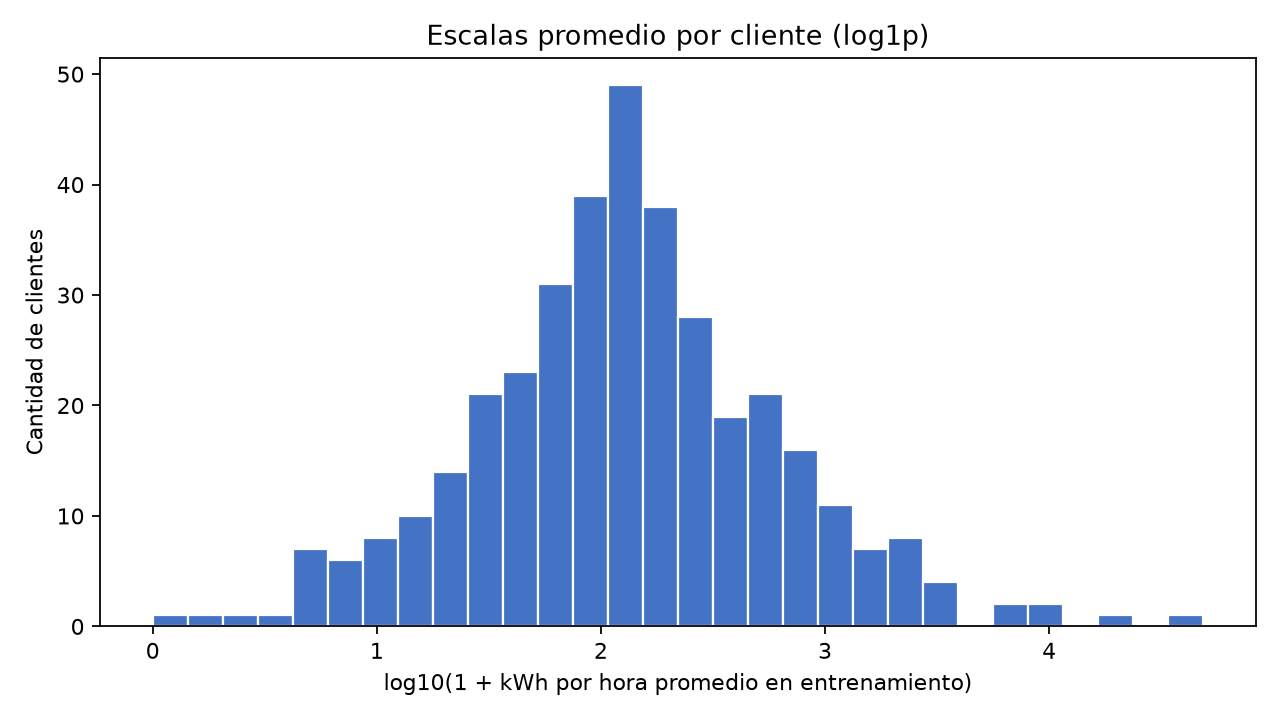

christmas_new_year.png


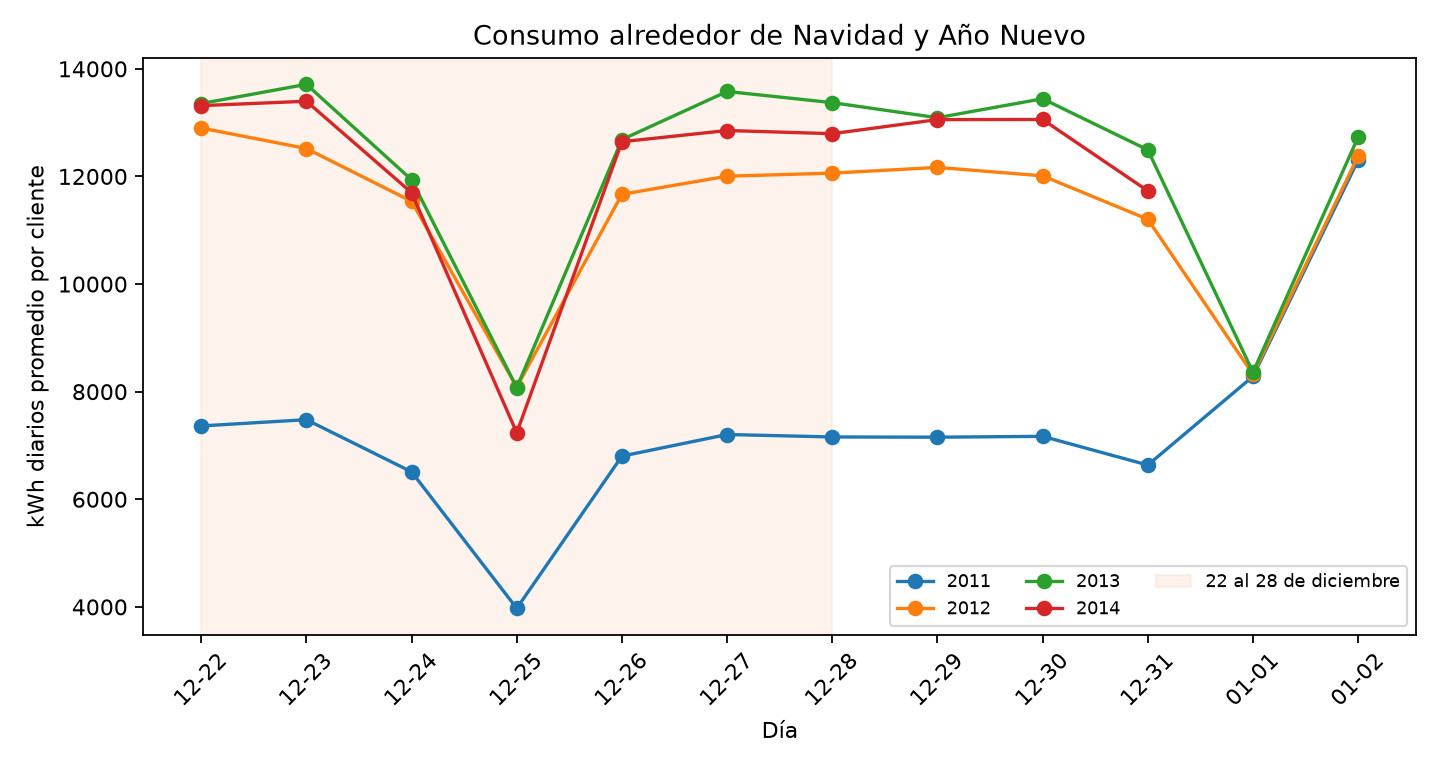

In [3]:
from IPython.display import Image, display

for name in (
    "hourly_weekly_profiles.png",
    "portugal_holidays.png",
    "client_scales.png",
    "christmas_new_year.png",
):
    print(name)
    display(Image(filename=str(ROOT / "outputs" / "figures" / "eda" / name)))

## Calendario y normalización

Se conserva la hora local sin zona horaria. La codificación cíclica usa 7 columnas para hora, día de semana, mes y feriado; la one-hot usa 44. Se elige cíclica para reducir dimensión y mantener cercanos los valores adyacentes, sin tratar enero y diciembre como categorías lejanas. Las embeddings se reservan para modelos deep que las justifiquen; añaden parámetros y aquí las categorías tienen ciclos conocidos. Las estadísticas globales o por cliente se ajustan solo entre 2012-01-01 y 2014-07-01; la normalización por ventana usa únicamente el historial de entrada.

In [4]:
from src.data.calendars import calendar_features
from src.data.splits import DEFAULT_SPLITS, temporal_split_origins, daily_backtest_origins
from src.training.scaling import TemporalScaler

cyclic = calendar_features(panel.timestamps, encoding="cyclic")
onehot = calendar_features(panel.timestamps, encoding="onehot")
train_start, train_end = DEFAULT_SPLITS["train"]
scaler = TemporalScaler("per_series").fit(
    panel.values, panel.timestamps, train_start=train_start, train_end=train_end
)
scaled_values = scaler.transform(panel.values)
restored_values = scaler.inverse_transform(scaled_values)
print({
    "features_ciclicas": cyclic.shape[1],
    "features_onehot": onehot.shape[1],
    "error_maximo_al_invertir": float(abs(restored_values - panel.values).max()),
    "fit_desde": scaler.fit_start_,
    "fit_hasta_exclusivo": scaler.fit_end_,
})

{'features_ciclicas': 7, 'features_onehot': 44, 'error_maximo_al_invertir': 0.004845699586439878, 'fit_desde': Timestamp('2012-01-01 00:00:00'), 'fit_hasta_exclusivo': Timestamp('2014-07-01 00:00:00')}


## Ventanas L=168 y H=24

Cada origen identifica la primera hora objetivo. El historial termina una hora antes del origen; las covariables futuras se entregan en un tensor separado. Los targets deben quedar enteros dentro de su split. El Dataset de entrenamiento usa stride 1; el backtest de prueba usa 92 orígenes diarios.

In [5]:
from src.data.windows import MultiSeriesWindowDataset

origins = temporal_split_origins(
    panel.timestamps, lookback=168, horizon=24, stride=1
)
daily_origins = daily_backtest_origins(panel.timestamps)
train_dataset = MultiSeriesWindowDataset(
    scaled_values,
    panel.timestamps,
    panel.client_ids,
    origins["train"][:2],
    lookback=168,
    horizon=24,
    calendar=cyclic,
)
sample = train_dataset[0]
print({
    "X": tuple(sample["X"].shape),
    "y": tuple(sample["y"].shape),
    "calendario_futuro": tuple(sample["future_calendar"].shape),
    "cliente": sample["unique_id"],
    "origen": sample["origin"],
    "primer_objetivo": sample["target_timestamps"][0],
    "ventanas_stride_1_por_split_y_cliente": {
        name: len(indices) for name, indices in origins.items()
    },
    "origenes_diarios_test": len(daily_origins),
})

{'X': (168, 8), 'y': (24,), 'calendario_futuro': (24, 7), 'cliente': 'MT_001', 'origen': '2012-01-01 00:00:00', 'primer_objetivo': '2012-01-01 00:00:00', 'ventanas_stride_1_por_split_y_cliente': {'train': 21865, 'validation': 2185, 'test': 2185}, 'origenes_diarios_test': 92}


## Pruebas contra fugas

Estas pruebas detectan targets compartidos o fuera de orden, normalización ajustada con datos posteriores, early stopping sobre test y calendarios futuros desalineados.

In [6]:
import subprocess

result = subprocess.run(
    [sys.executable, "-m", "pytest", "-q"],
    cwd=ROOT,
    check=True,
    capture_output=True,
    text=True,
)
print(result.stdout)

..........................                                               [100%]
26 passed in 4.57s



## Fase 3: evaluación común

El evaluador principal ajusta una vez y pronostica las 24 horas desde las 00:00 para cada uno de los 92 orígenes diarios de prueba. El historial termina a las 23:00 del día anterior; el calendario futuro se entrega separado y nunca incluye consumo objetivo. Las variantes con reentrenamiento mensual forman una evaluación distinta.

MAE y RMSE se calculan en kWh. WAPE se reporta en porcentaje; MAPE excluye y cuenta targets con valor absoluto menor o igual a 1e-8. MASE usa la diferencia estacional de 24 horas calculada solo con entrenamiento; las series con denominador cero quedan indefinidas, sin epsilon.

Las decisiones de interfaz, teacher forcing, RevIN, cuantiles, pinball loss y ejemplos de LSTM, GRU, Conv1d y Transformer están en [docs/fase3_evaluacion.md](../docs/fase3_evaluacion.md). Referencias: [PyTorch RNN](https://docs.pytorch.org/docs/2.15/generated/torch.nn.LSTM.html), [StatsForecast](https://nixtlaverse.nixtla.io/statsforecast/src/core/core.html), [NeuralForecast](https://nixtlaverse.nixtla.io/neuralforecast/docs/capabilities/cross_validation.html) y [Chronos](https://github.com/amazon-science/chronos-forecasting).

## Fase 4: baselines y modelos globales

Se implementaron Naive, SeasonalNaive (24 y 168), AutoETS(A,A,A), LightGBM directo a 24 pasos, MLP multi-salida, DLinear y NLinear. LightGBM usa rezagos 1 a 24 y 168 con covariables del calendario del paso pronosticado. Los modelos propios ajustan el escalado solo con entrenamiento; la validaci?n selecciona la ?poca y las predicciones vuelven a kWh antes de medir.

El runner guarda predicciones completas, m?tricas uniformes, curvas y checkpoints en `outputs/`. Ejecuta `python -m src.experiments.phase4` para la matriz completa. La opci?n `--smoke` usa hasta ocho clientes y reduce ?pocas, ventanas y or?genes para revisar el pipeline, por lo que sus m?tricas no son resultados finales. Los detalles est?n en `docs/fase4_modelos.md`.

In [ ]:
from src.experiments.phase4 import build_experiments

fase4_experimentos = build_experiments(
    ROOT / "outputs" / "models" / "phase4", smoke=True
)
pd.DataFrame(
    [
        {"experimento": name, "modelo": name.split("-")[0], "L": config["lookback"], "H": config["horizon"]}
        for name, _, config in fase4_experimentos
    ]
)